# SAMPIClyser Analysis

Start by loading the required libraries.
This repositories implements "database" libraries to get all run information

In [12]:
from pathlib import Path

In [13]:
from PPS_TB_202507_RunDB import runs_to_configs, run_config_info
from PPS_TB_202507_RunDB import run_info as run_info_dict

Define which run you want to process and load the run information

In [7]:
!pip list --user sampiclyser click matplotlib  mplhep natsort numpy pandas pyarrow pyyaml scipy  termcolor uproot 


Package              Version
-------------------- -------
AWAKE-ANALYSIS-TOOLS 0.0.2
click                8.5.0
matplotlib           3.11.2
mplhep               1.3.3
natsort              8.4.0
numexpr              2.14.2
numpy                2.5.3
pandas               3.0.5
pip                  26.2.1
pyarrow              25.0.1
pyawake              0.0.5
PyYAML               6.0.3
SAMPIClyser          0.2.1
scipy                1.18.1
termcolor            3.3.0
uproot               5.7.6


In [9]:
import os

In [10]:
os.environ['HOME']

'/eos/user/c/cmora'

In [11]:
oldpath=os.environ['PATH']
os.environ['PATH']=os.environ['HOME']+'/.local/bin:'+oldpath
os.environ['PATH']

'/eos/user/c/cmora/.local/bin:/cvmfs/sft.cern.ch/lcg/views/LCG_110_swan/x86_64-el9-gcc13-opt/scripts:/cvmfs/sft.cern.ch/lcg/views/LCG_110_swan/x86_64-el9-gcc13-opt/bin:/cvmfs/sft.cern.ch/lcg/releases/gcc/13.1.0-b3d18/x86_64-el9/bin:/cvmfs/sft.cern.ch/lcg/releases/binutils/2.40-acaab/x86_64-el9/bin:/opt/conda/bin:/sbin:/bin:/usr/sbin:/usr/bin:/usr/local/bin/swan/nb_term_bin/'

In [16]:
os.listdir('./PPS2_LGAD_Testbeam_202507')

['run1.parquet',
 'run1.root',
 'run2.parquet',
 'run2.root',
 'run3.parquet',
 'run3.root',
 'run4.parquet',
 'run4.root',
 'run5.parquet',
 'run5.root']

In [8]:
run_to_process = "Run002"
run_label="(H6 Test Beam, July 2025)"
parquet_file = Path(f"./{run_to_process}.parquet")

run_info = run_info_dict[run_to_process]
config_key = runs_to_configs[run_to_process]
config_info = run_config_info[config_key]

## Hits Per Channel

In [9]:
from sampiclyser.sampic_tools import get_channel_hits
from sampiclyser.sampic_tools import plot_channel_hits

In [10]:
hit_summary = get_channel_hits(parquet_file)
hit_summary

,Channel,Hits
0,0,436
1,1,822
2,2,1297
3,3,661
4,4,1002
5,5,2718
6,6,2411
7,7,684
8,8,489
9,9,546


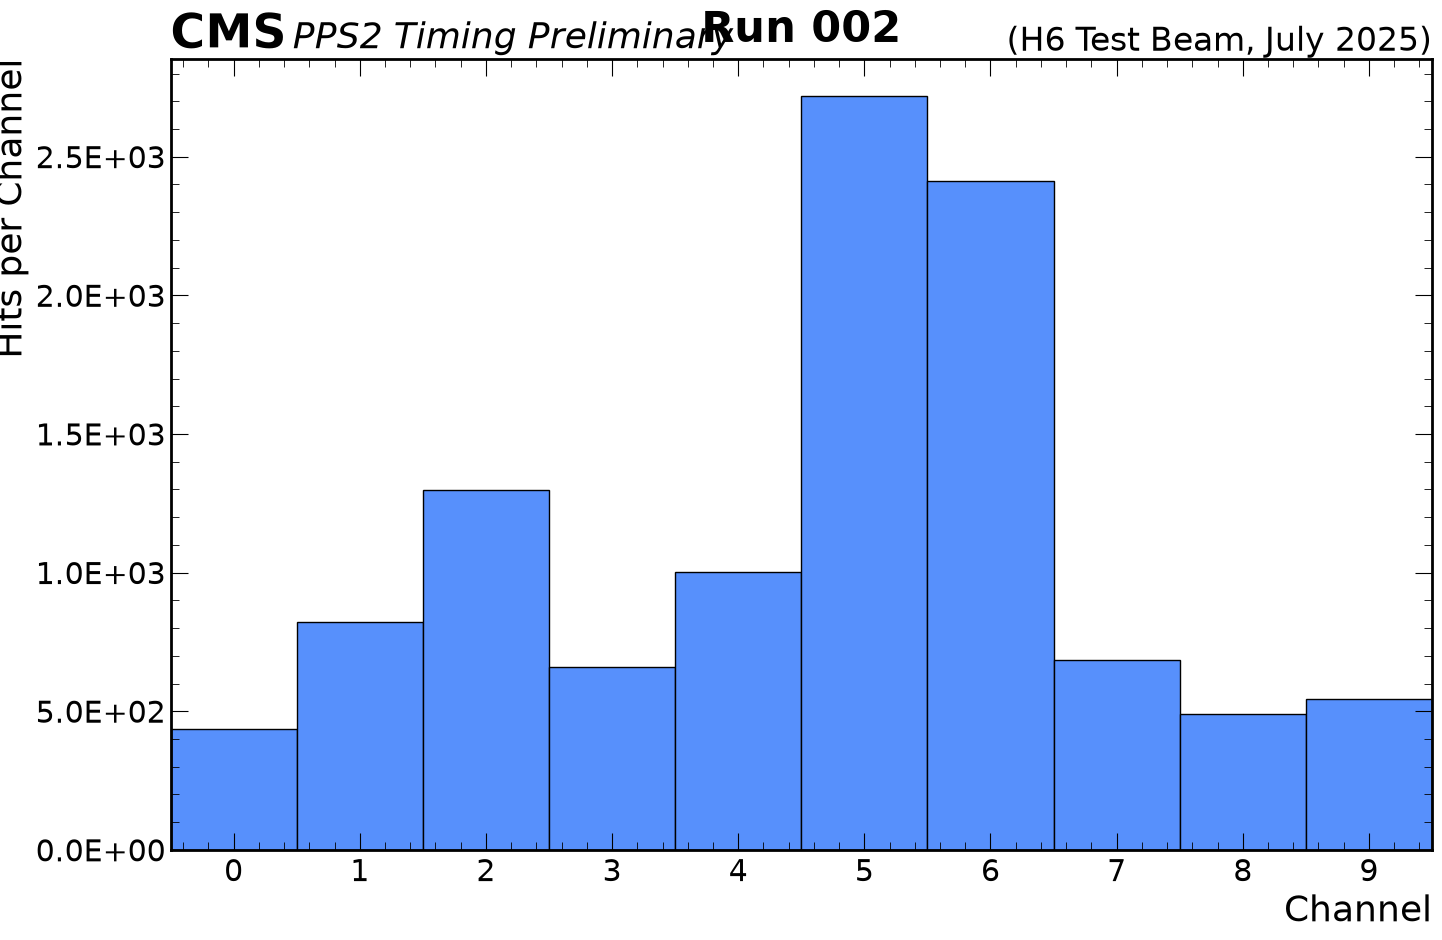

In [11]:
title = run_info.name
fig = plot_channel_hits(hit_summary,0,9,label="PPS2 Timing Preliminary", rlabel=run_label,figsize=(15,10),title=title)

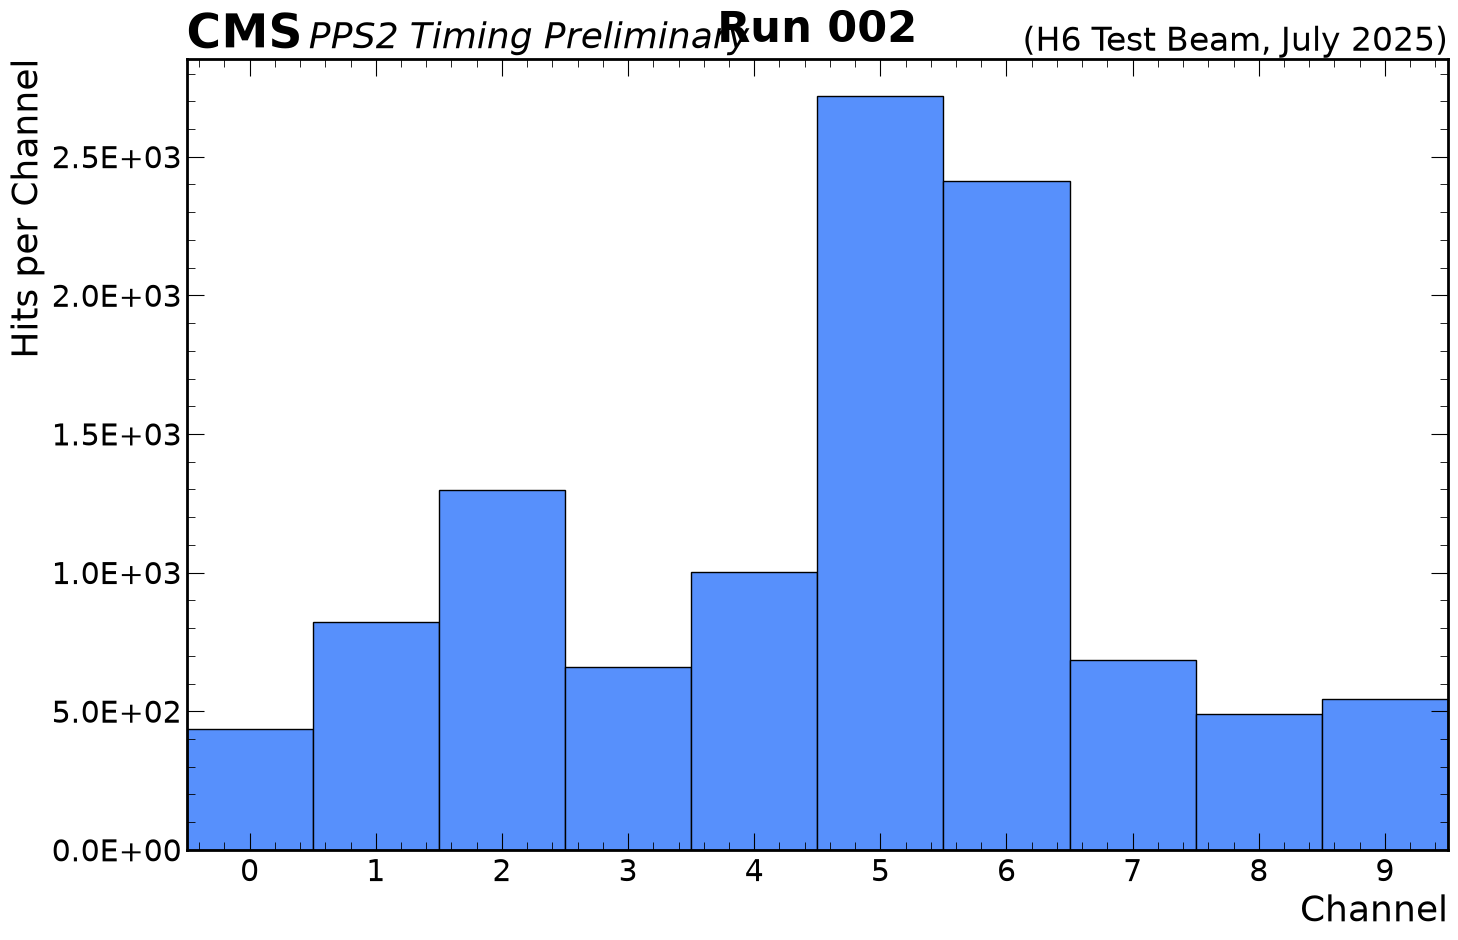

In [12]:
fig

## Draw Hitmap

In [13]:
from sampiclyser.sensor_hitmaps import plot_hitmap

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


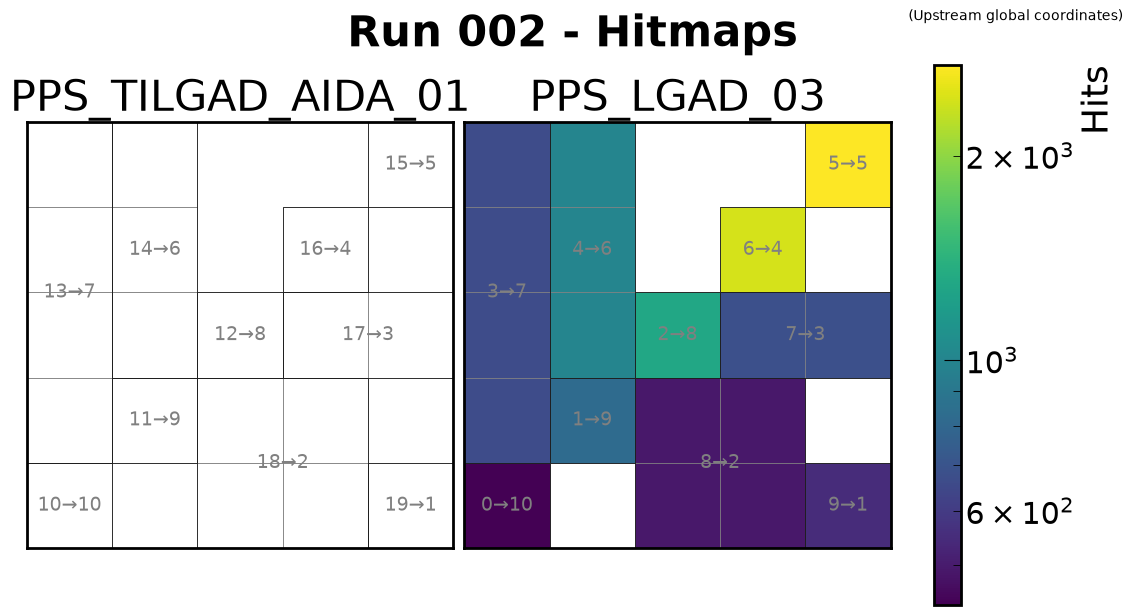

In [14]:
plot_title = run_info.name + " - Hitmaps"

board_spec = [config_info.board_spec[board] for board in config_info.board_order]

fig = plot_hitmap(
    hit_summary,
    specs=board_spec,
    layout=(1, 2),
    figsize=(11,6),
    log_z = True,
    title = plot_title,
    do_sampic_ch = True,
    do_board_ch= True,
    coordinates="global",
)

fig

## Overall Hit Rate

In [15]:
from sampiclyser.sampic_tools import plot_hit_rate
import datetime

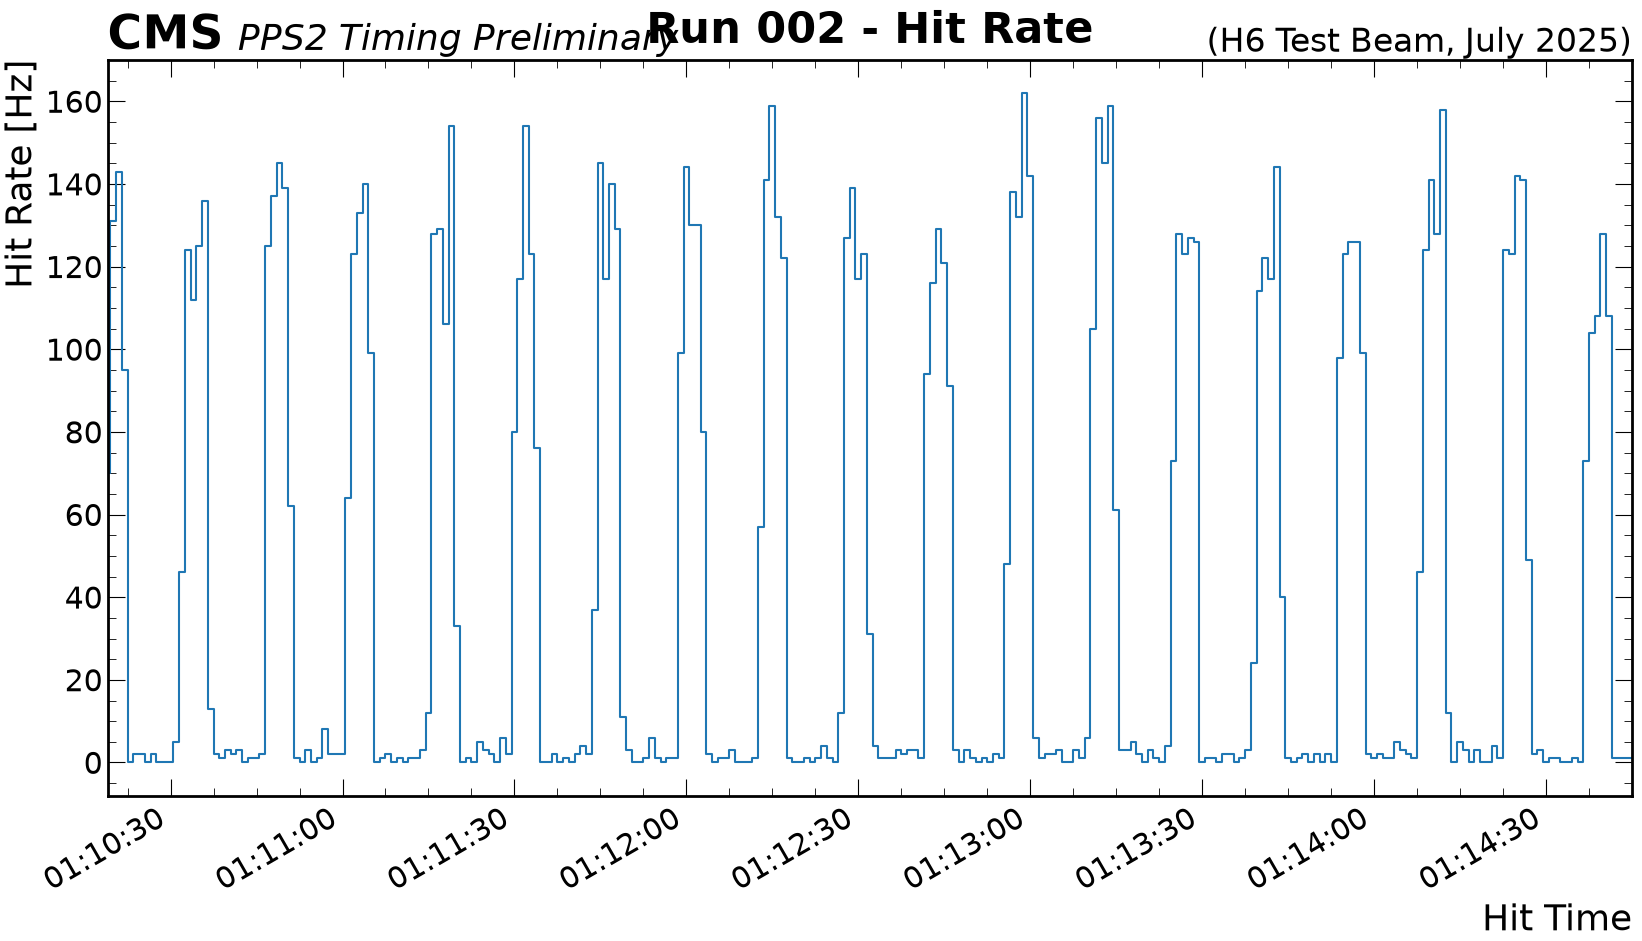

In [16]:
plot_title = run_info.name + " - Hit Rate"

fig = plot_hit_rate(
    parquet_file,
    plot_hits=False,
    bin_size=1,
    #start_time=datetime.datetime(2025, 5, 15, 23, 27),
    #end_time=datetime.datetime(2025, 5, 15, 23, 57),
    label="PPS2 Timing Preliminary",
    rlabel=run_label,
    #log_y=True,
    figsize = (17, 10),
    title=plot_title,
    )

fig

## Channel Hit Rate

In [17]:
from sampiclyser import plot_channel_hit_rate

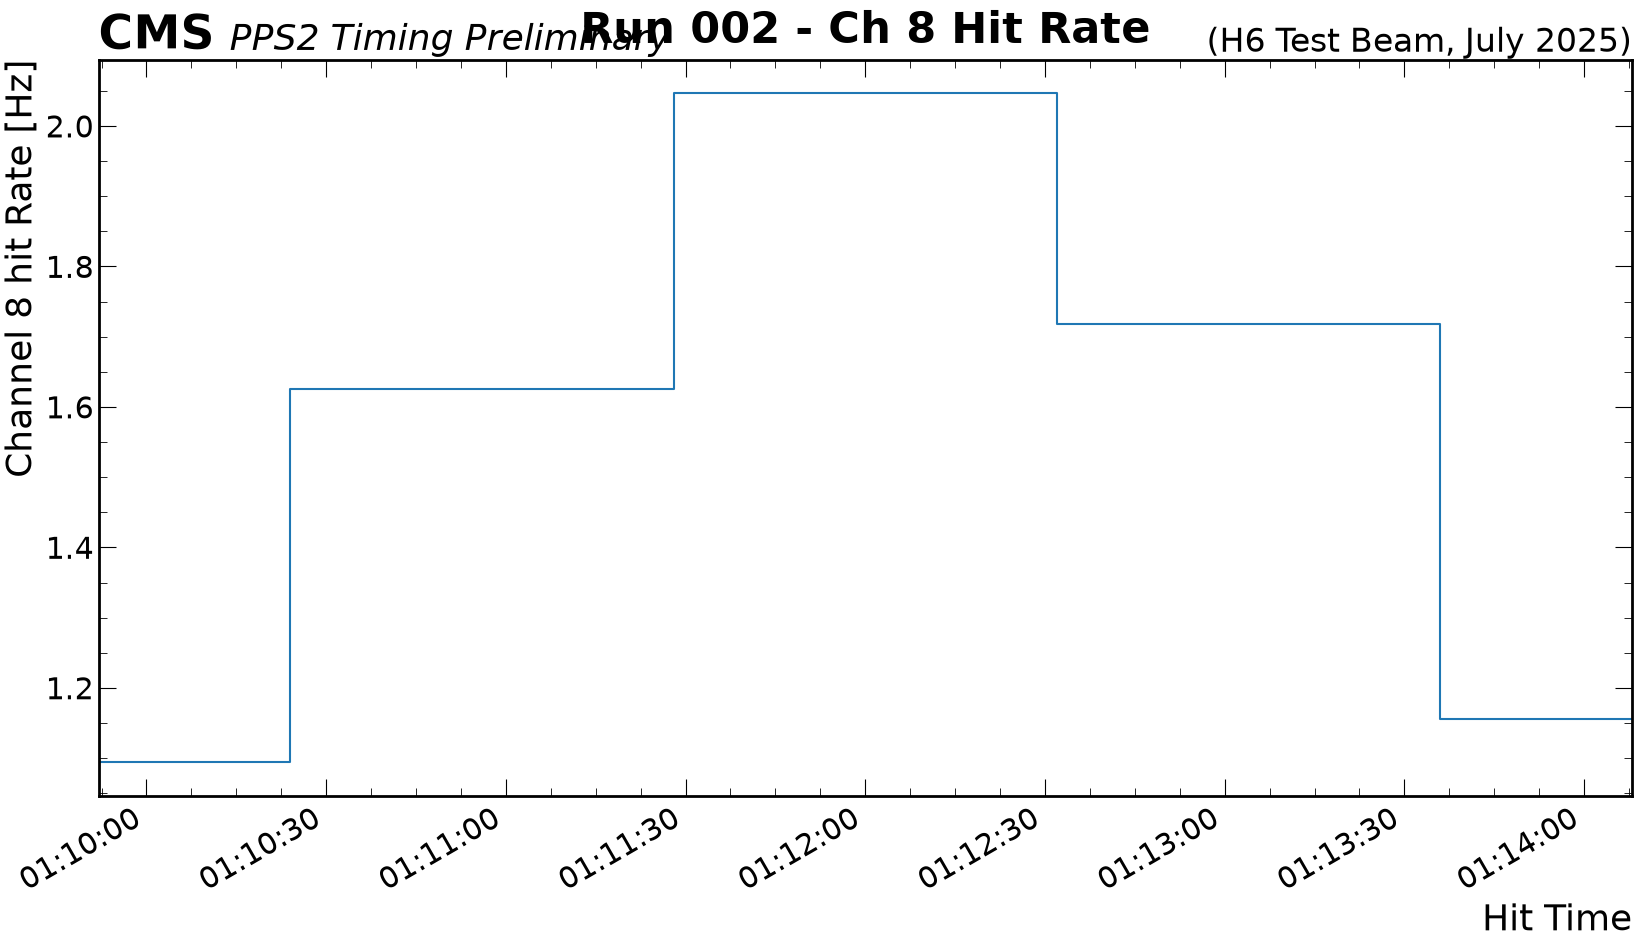

In [18]:
channel = 8
plot_title = run_info.name + f" - Ch {channel} Hit Rate"

plot_channel_hit_rate(
    parquet_file,
    channel = channel,
    bin_size=64,
    #start_time=datetime.datetime(2025, 5, 15, 23, 27),
    #end_time=datetime.datetime(2025, 5, 15, 23, 57),
    #start_time=datetime.datetime(2025, 5, 17, 1, 10),
    #end_time=datetime.datetime(2025, 5, 17, 1, 30),
    label="PPS2 Timing Preliminary",
    rlabel=run_label,
    #log_y=True,
    figsize = (17, 10),
    title=plot_title,
)

## Plot Some waveforms

In [19]:
from sampiclyser.sampic_tools import plot_channel_waveforms

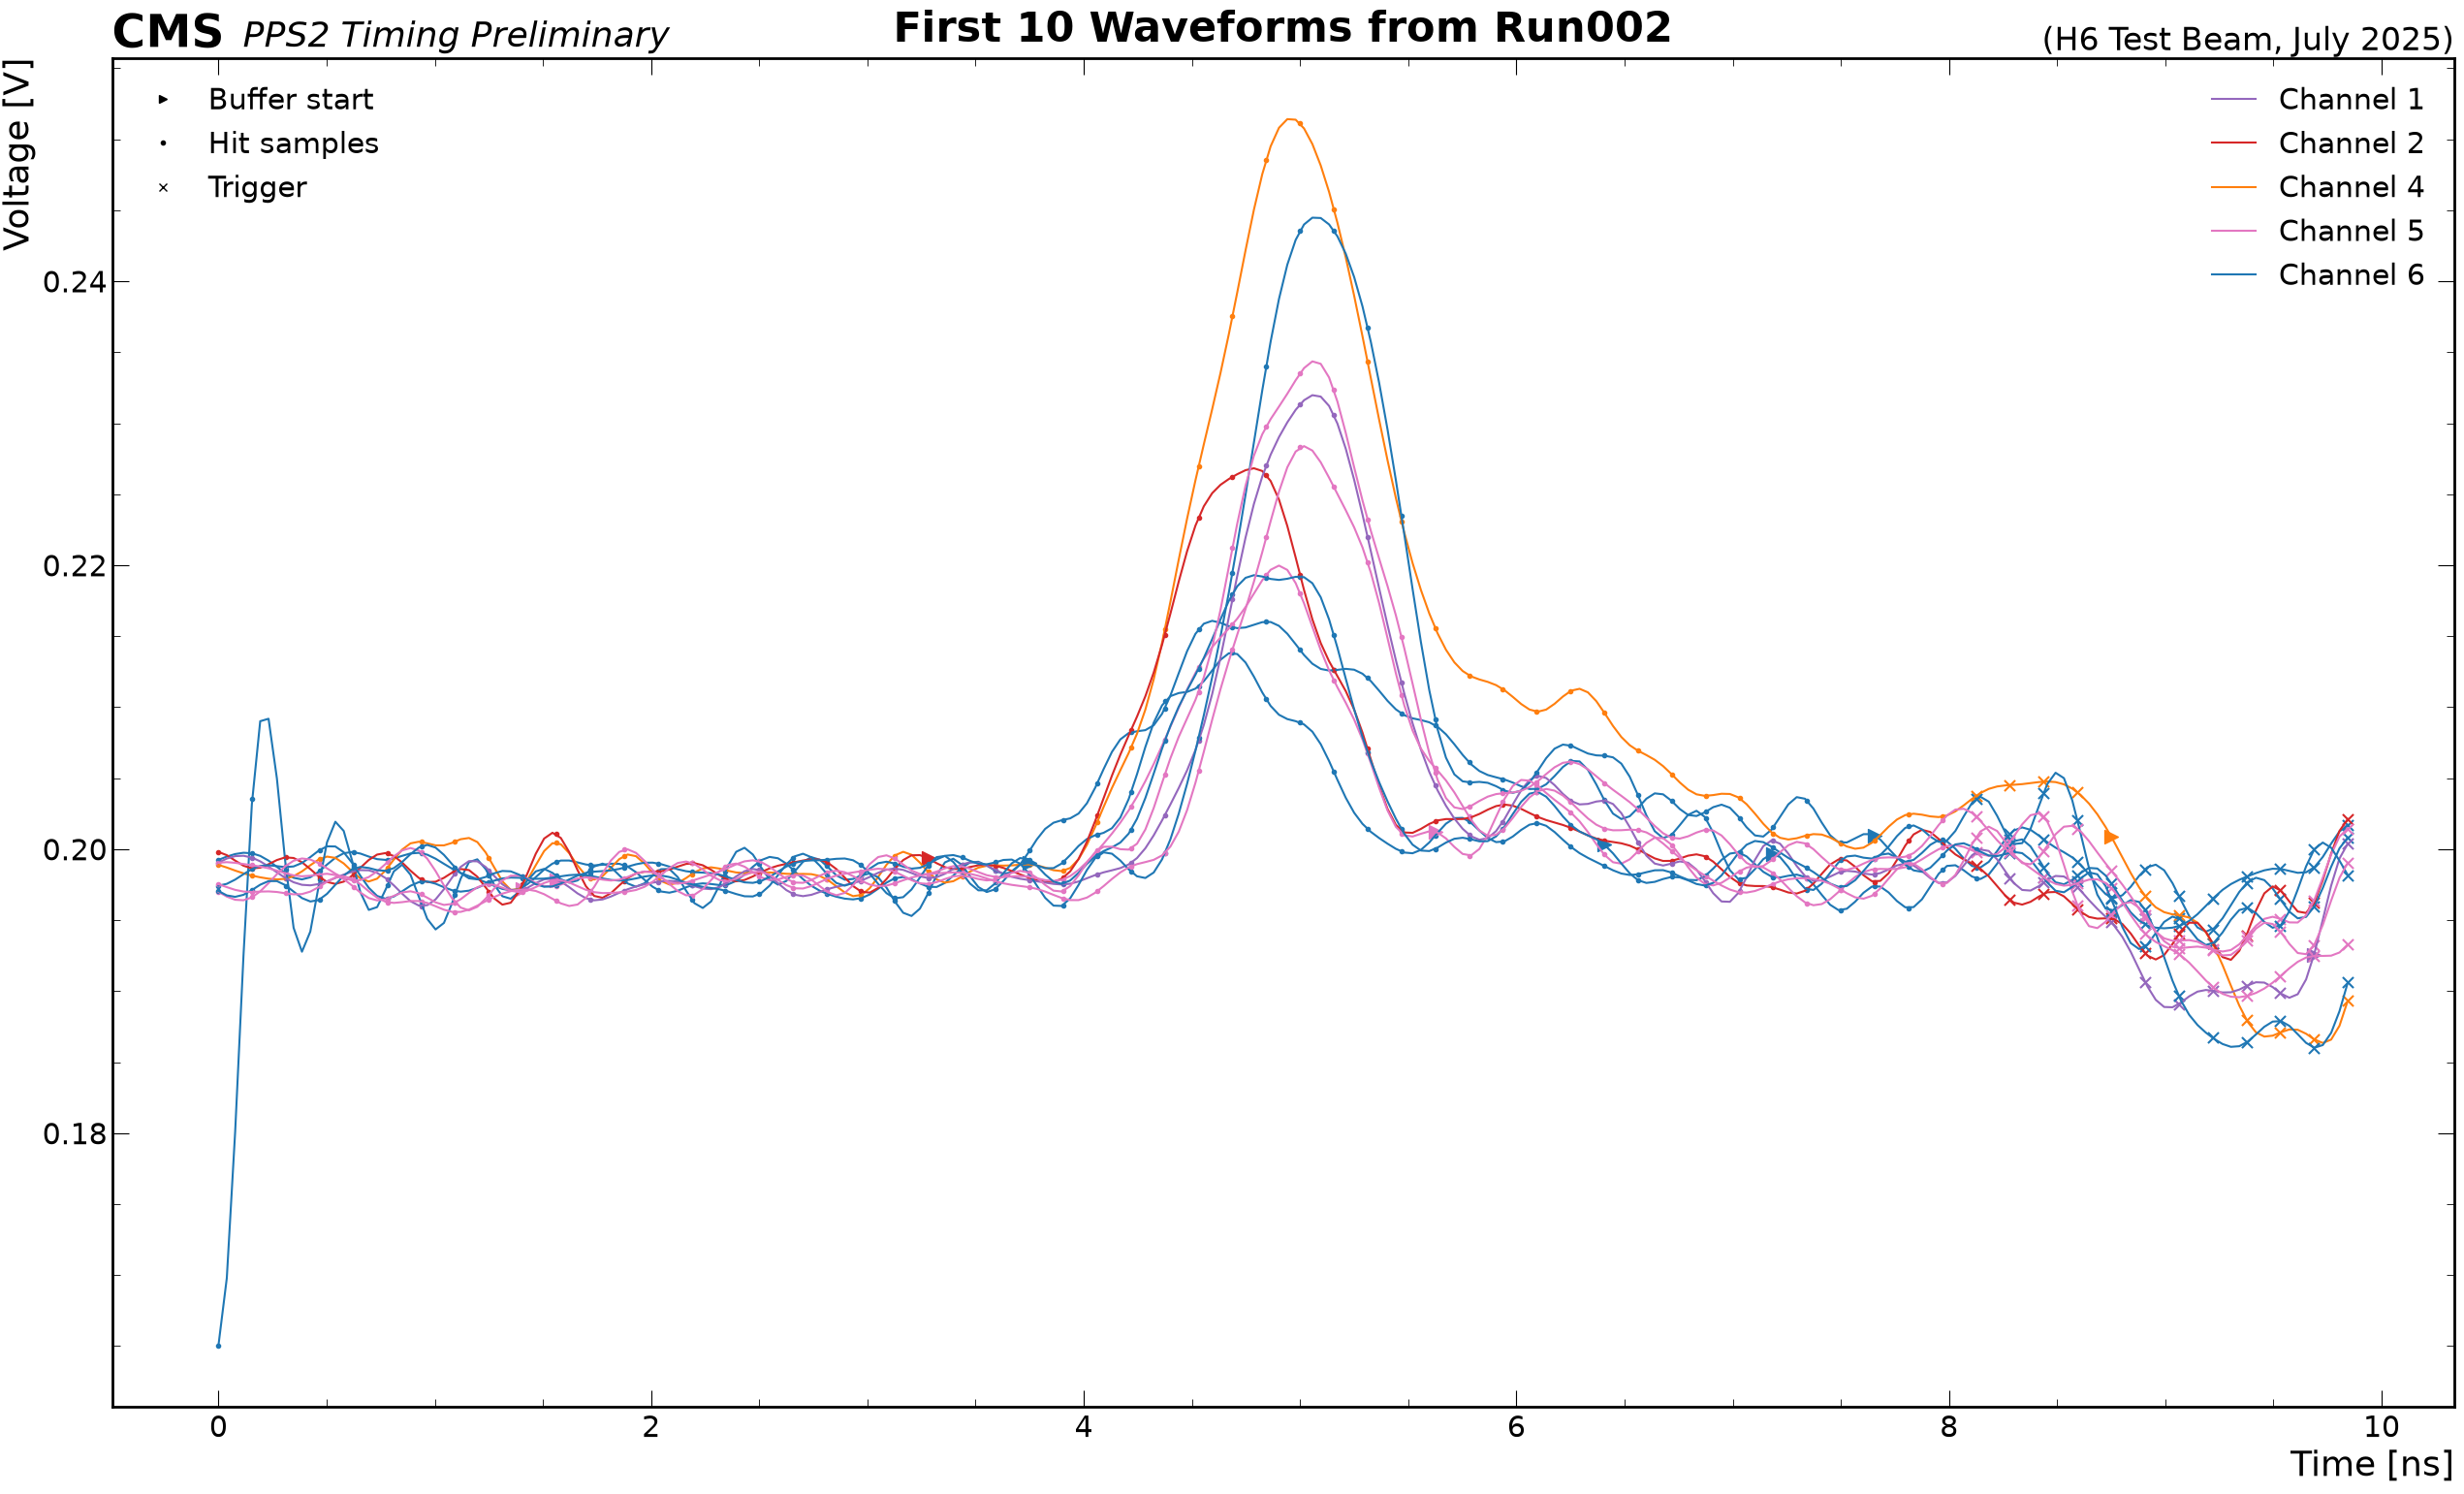

In [20]:
plot_channel_waveforms(
    #Path("test.parquet"),
    parquet_file,
    interpolation_method='sinc',
    cmap='tab10',
    figsize=(26,16),
    first_hit=0,
    num_hits=10,
    #channel_filter=[9],
    #channel_filter=[4, 5, 7],
    label="PPS2 Timing Preliminary",
    rlabel=run_label,
    log_y=False,
    #title=plot_title,
    is_data=True,
    file_name_id=run_to_process,
    )